<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ch04_training_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ch-4 Training Models (152 -196)

1. The Normal Equation — a direct, closed-form formula that computes optimal linear regression weights in one step (no iteration).

2. Computational Complexity — why the Normal Equation gets slow as features grow, motivating iterative methods.

3. Gradient Descent (concept) — an iterative optimization algorithm that tweaks parameters step-by-step to minimize a cost function.

4. Batch Gradient Descent — computes the gradient using the entire training set at every step; accurate but slow on big data.

5. Stochastic Gradient Descent (SGD) — computes the gradient using just one random instance per step; fast and noisy, helps escape local minima.

6. Mini-batch Gradient Descent — a middle ground: computes gradients on small random subsets of data per step.

7. Learning Rate & Convergence — how the step size affects whether/how fast Gradient Descent finds the minimum.

8. Polynomial Regression — fitting curved (nonlinear) data by adding powers of features as new features to a linear model.

9. Learning Curves — plots of training vs. validation error used to diagnose underfitting or overfitting.

10. Regularized Linear Models — techniques that constrain a model's weights to reduce overfitting:

* Ridge Regression — adds an L2 penalty (squared weights) to the cost function.
* Lasso Regression — adds an L1 penalty (absolute weights); can zero out less-useful features entirely.
* Elastic Net — a blend of Ridge and Lasso penalties.

11. Early Stopping — halting training as soon as validation error starts rising, to prevent overfitting.

12. Logistic Regression — a linear model adapted for classification, outputting probabilities via the sigmoid function.

13. Softmax Regression — the multiclass extension of Logistic Regression, outputting a probability distribution over several classes.

## 0.Genral Knowledge

1. `θ` = the model's parameters (the numbers being adjusted) — in gradient descent, it's the same θ (θ₀, θ₁, ...) being tuned step-by-step to reduce error.

2. `Bias/intercept (θ₀):` the starting value/prediction when all inputs are 0. Shifts the line up or down.

3. `Weight/slope (θ₁):` how much the output changes per unit increase in input. Controls the line's steepness/tilt.

* Example:
y^ = 4+3x

* θ₀ = 4 → if x=0, prediction = 4 (line starts at 4 on y-axis)
* θ₁ = 3 → for every +1 in x, prediction increases by 3






4. `@` = matrix multiplication operator (same as np.matmul)

5. `Epoch` - every iteration of the training step is called an epoch .

6. `Convex function:` a bowl-shaped curve with one single minimum — no bumps, no local minimums to get stuck in. If a cost function is convex, gradient descent is guaranteed to reach the global minimum (the best possible θ), given enough time and the right learning rate.

Terminologies

1. `Gradient Descent` is an iterative algorithm that finds the best θ values by repeatedly adjusting them to reduce error.

2. `Convergence rate`: how fast gradient descent reaches the minimum (how many steps/epochs needed).

* Depends on learning rate (too small → slow; too large → overshoots/diverges).
* Depends on the shape of the cost function — if features have very different scales, the "bowl" becomes elongated/skewed, making convergence slower (that's why feature scaling helps speed things up).

## 1.Linear Regression

In chapter 1 we looked at a simple linear model of life satisfaction.

    life _ satisfaction = θ0 + θ1 × GDP_per_capita

*  This model is just a linear function of the input feature `GDP_per_capita`. θ0 and θ1 are the model’s parameters.

* θ0 (bias/intercept)

* θ1 (weight/slope)

    linear model = weight_sum (input_features) + bias(intercept)  

### 1.1 Linear regression model prediction

a linear model makes a prediction by simply computing a weighted sum of the input features, plus a
constant called the bias term (also called the intercept term)

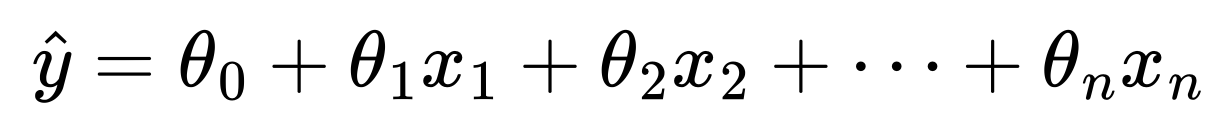

In this equation:

* ŷ is the predicted value.
* n is the number of features.
* xi is the i^th feature value.
* θj is the jth model parameter, including the bias term θ0 and the feature weights θ1, θ2,
⋯
, θn.

### 1.2 Lnear regression model prediction (vectorized form)


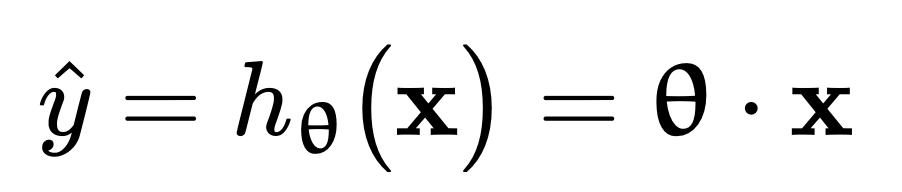

In this equation:
* hθ is the hypothesis function, using the model parameters θ.
* θ is the model’s parameter vector, containing the bias term θ0 and the feature weights θ1 to θn.
* x is the instance’s feature vector, containing x0 to xn, with x0 always equal to 1.
* θ · x is the dot product of the vectors θ and x, which is equal to θ0x0 + θ1x1 + θ2x2 + ... + θnxn.

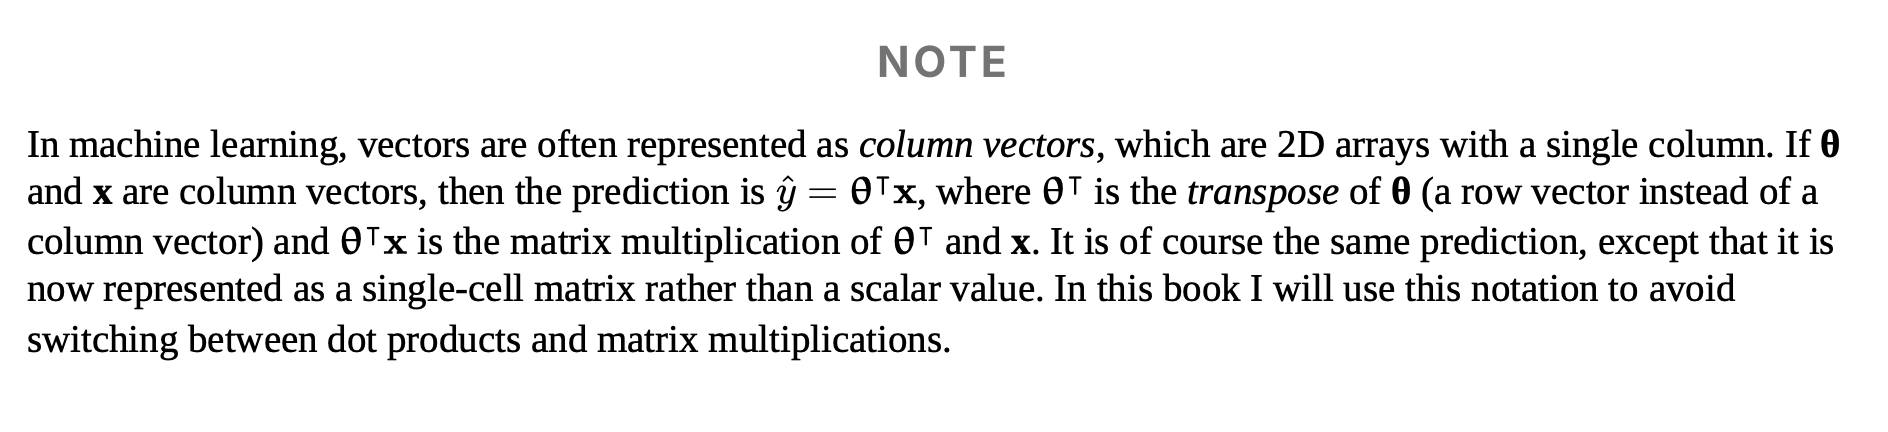

side topic

* Training a model includes
1. Setting it's parameters so that model best fits the training set.
2. checking the performance measure of a regression model is RMSError .
3. To train = find the Q that minimize the RMSE .

* Tip :- Minimizing MSE(mean square error) is simpler than minimizing RMSE .


### 1.3 MSE cost fn for a linear regression model


The MSE of a linear regression hypothesis hθ on a training set X is calculated using

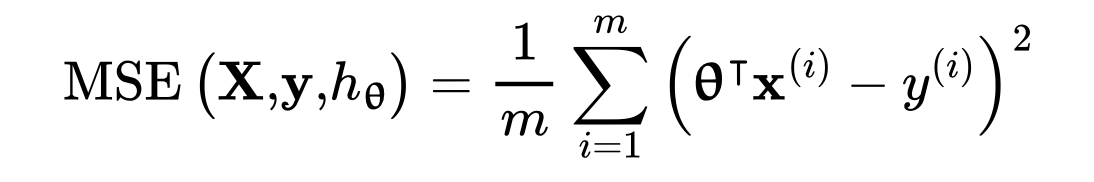

### 1.4 The Normal Equation

* for finding the value of θ that minimizes the MSE , there is a mathematical equation and gives us the result direclty and this is called the normal equation .

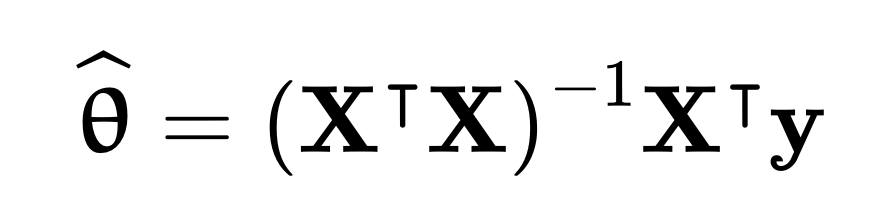

In this equation:
* ˆ 𝛉 is the value of θ that minimizes the cost function.

* y is the vector of target values containing y(1) to y(m)

### 1.5 Generating Linear-looking data

To test the first equation

life _ satisfaction = θ0 + θ1 × GDP_per_capita

In [ ]:
import numpy as np

# get the same "random" numbers every time you run it.
rng = np.random.default_rng(seed = 42)
m = 200 # np. of instances / no. of distances

X = 2 * rng.random((m,1)) # column vector
# X is the input feature
### Note : rng creates values between [0,1) but we multiplied with 2 so it [0,2)

y = 4 + 3 * X + rng.standard_normal((m,1)) # column vector
# here m(slope) = 3 and c(intercept) = 4
# Note:- here in y line we added rng.standard_normal((m,1)) ,
# becuase we wanted to add noise ,as in the real world data is not so clean


What rng.standard_normal((m,1)) does:


Generates 200 random numbers from a normal (Gaussian) distribution — mean 0, standard deviation 1. So most values are small (close to 0), some are slightly bigger (positive or negative), following a bell curve.

In [ ]:
m

200

NOTE:- y = 4 + 3 * X + rng.
standard_normal((m,1))

* This builds the target values using the true underlying line y = 4 + 3X, then adds Gaussian noise (standard_normal = random values from a normal distribution, mean 0, std 1) so the points don't perfectly sit on the line — they scatter around it. That's exactly the noisy linear pattern in your image.

* So the "true" model is intercept = 4, slope = 3, and the whole point of the chapter is: can Linear Regression recover something close to θ₀=4, θ₁=3 just from the noisy data?

In [ ]:
print(X.shape)
print(y.shape)

(200, 1)
(200, 1)


In [ ]:
X[:5] , y[:5]

(array([[1.5479121 ],
        [0.87775688],
        [1.71719584],
        [1.39473606],
        [0.1883547 ]]),
 array([[9.28706309],
        [6.23866552],
        [9.14646565],
        [8.02076528],
        [4.90263864]]))

/tmp/ipykernel_2934/1746174880.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X, y, cmap = plt.cm.RdYlBu)


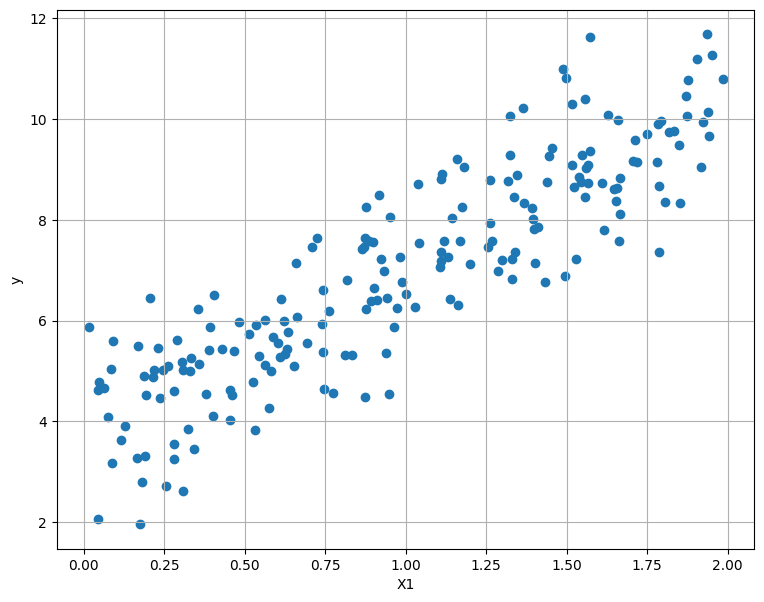

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize = (9,7))
plt.scatter(X, y, cmap = plt.cm.RdYlBu)
plt.xlabel("X1")
plt.ylabel("y")
plt.grid(True)
plt.show()

Now :-  
* computing ˆ 𝛉 using the normal equation.

* Using the inv() fn from the linear algebra module (np.linalg) for computing the inverse of a matrix .

* @ operator for matrix multiplication:

Normal Equation: $θ̂$ = $(X^ᵗ · X)^⁻¹ · X^ᵗ · y$





In [ ]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X) # add x0 = 1 to each instance
# means in a format of [[1, 0.19],
#                       [1, 1.20]] like this

theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y # this right here is the formula
# np means numpy  , linalg.inv means invert that square matrix
# @ X_b.T @ y multiply X_b transpose and y


print(theta_best)
# array([[3.69084138],
#        [3.32960458]])
# True values were θ0=4, θ1=3 — close, but noise prevents exact recovery

[[3.69084138]
 [3.32960458]]


Note:
* add_dummy_feature(X) -

adds a column of 1s to X, so each row becomes [1, x]. This lets θ₀ (bias) get multiplied by 1 in the matrix math. Shape: (200,1) → (200,2).

In [ ]:
# Let's make an prediction using 𝛉ˆ
X_new = np.array([[0], [2] ]) # testing x on 0 and 2 for predicting y
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best # @ = used for matrix multiplication
y_predict


array([[ 3.69084138],
       [10.35005055]])

The model learned: ŷ = θ₀ + θ₁·x = 3.69 + 3.33·x

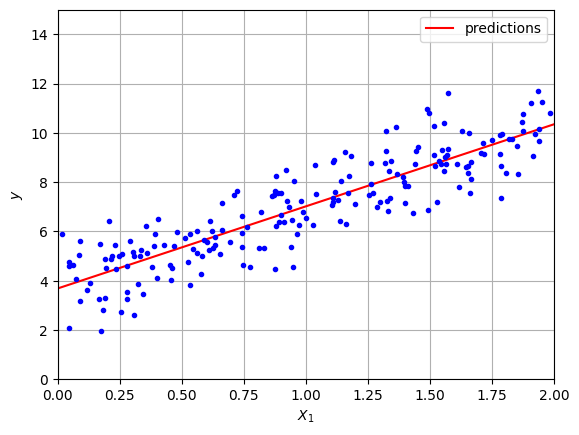

In [ ]:
# let's plot this model's prediction
import matplotlib.pyplot as plt
plt.plot(X_new, y_predict, "r-", label="predictions") # red line: model's fitted line (2 points define it)
plt.plot(X, y, "b.") # blue dots: original noisy training data (200 points)
plt.xlabel("$X_1$")
plt.ylabel("$y$")
plt.grid(True)
plt.legend()
plt.axis([0, 2, 0, 15])
plt.show()

* Let's test out Linear regression using Scikit-Learn as it's relatively starightforward

The model learned: ŷ = θ₀ + θ₁·x = 3.69 + 3.33·x , below code in this type of form

In [ ]:
from sklearn.linear_model import LinearRegression

# s2 = instance creation
lin_reg = LinearRegression()
# s3 - fit so that it can learn
lin_reg.fit(X,y)

# s4 - checking out the intercept and coefficient/slope
print(lin_reg.intercept_) # bias
print(lin_reg.coef_) # slope / weight

# s5 - Let's do prediction
print(lin_reg.predict(X_new))


[3.69084138]
[[3.32960458]]
[[ 3.69084138]
 [10.35005055]]


`NOTE`
* Scikit-learn seprated the bias term (intercept_) term from the feature weight (coef_)



### 1.6 General Knowledge

1. Intercept (c): value of y when x=0. Where the line crosses the y-axis.

2. Coefficient/slope (m): how much y changes per unit increase in x. Controls the line's steepness.

Example: y = 3x + 4

* Intercept = 4 (line crosses y-axis at 4)
* Coefficient/slope = 3 (for every +1 in x, y increases by 3)

## SVD(Singular Value Decomposition)

way of breaking down any matrix into 3 simple matrices .

    Formula :  A=UΣV^T

* Rotate(U)
* Strech/scale (Σ) - singular values , more values = more important direction
* Rotate again (V^T)


`Advantages` of using SVD -

1. In normal equation , we need to invert the matrix (np.linalg.inv), which can be failed - fail happens when "Singular matrix" and it can't be inverted

* e.g - Duplicate values , highly related features

2. `SVD` avoids this issue by avoiding it , by not inverting ,  by safely bringing out the best Theta(Q) and ignoring the less-important directions , noise

The LinearRegression class is based on the `scipy.linalg.lstsq()` function (the name stabds for `"least squares"`)

`NOTE`

    np.linalg.lstsq(X_b, y , rcond = 1e-6)

solves the same problem like the normal equation i.e finding the best θ - but with using the `SVD(Singular Value Decomposition)` internally instead of directly inverting X_b.T @ X_b

In [ ]:
# Let's test it out
theta_best_svd , residuals, rank , s = np.linalg.lstsq(X_b, y , rcond = 1e-6)
theta_best_svd # return 4 things
# theta_best_svd = the best Q(theta) same as theta_best from normal equation,
# residuals - leftover error(often empty here) ,
# rank = rank of X_b , how many independent directions/columns X_b actually has
# s = singular values of SVD

# rcond for ignoring the less important directions ,noise
# rconf = 1e-6 cutoff threshold; tiny singular values below this
# are treated as zero (handles near-singular/unstable matrices safely)

array([[3.69084138],
       [3.32960458]])

`NOTE`

The pseudoinverse is computed as X+ = VΣ+U⊺
. To compute the matrix Σ+, the algorithm
takes Σ and sets to zero all values smaller than a tiny threshold value, then it replaces all the nonzero values with their
inverse, and finally it transposes the resulting matrix.


This approach is more efficient than computing the normal
equation, plus it handles edge cases nicely: indeed, the normal equation may not work if the matrix X⊺X is not invertible
(i.e., singular), such as if m < n or if some features are redundant, but the pseudoinverse is always defined.

This function computes ˆ 𝛉 = X+y, where X+ is the pseudoinverse of X (specifically, the Moore–Penrose inverse). You
can use np.linalg.pinv() to compute the pseudoinverse directly:

In [ ]:
# let's try this new approach
# another way then SVD to check , which is quite simple
np.linalg.pinv(X_b) @ y
# pseudoinverse method: same θ as Normal Equation, but safer for non-square/singular matrices

array([[3.69084138],
       [3.32960458]])

### 1.7 Computational Complexity

* The normal equation computes the inverse of X^⊺ X, which is an (n + 1) × (n + 1) matrix (where n is the number of
features). The computational complexity of inverting such a matrix is typically about O(n^2.4) to O(n^3), depending on the
implementation.


* In other words, if you double the number of features, you multiply the computation time by roughly 2^2.4
= 5.3 to 2^3 = 8.


The SVD approach used by Scikit-Learn’s LinearRegression class is about O(n^2). If you double the number of
features, you multiply the computation time by roughly 4.

`NOTE`

once Linear regression model is trained(using the normal equation or any other algorithm),
predictions are very fast :

the computational complexity is linear with regard to both the number of instances you want to make
predictions on and the number of features. In other words, making `predictions on twice as many instances` (or twice as
many features) will take roughly `twice` as much time.

## 2.Different way to train a Linear regression model

(best suited for large no. of features or for many instances to fit in the memory).


### 2.1 Gradient Descent (159)

Basic idea - Tweaking parameters iteratively in order to minimize a cost function

`NOTE`

1. When using gradient descent, you should ensure that all features have a similar scale (e.g., using Scikit-Learn’s
StandardScaler class), or else it will take much longer to converge.

### 2.2 Batch Gradient Descent

* Models often have multiple parameters (θ₀, θ₁, θ₂, ... θₙ), not just one.
* To do gradient descent, you need to know how the cost function (MSE) changes for each θⱼ individually.
* This "how much cost changes if you do a tiny push/small change. just θⱼ a little" = partial derivative (∂ MSE(θ) / ∂θj)

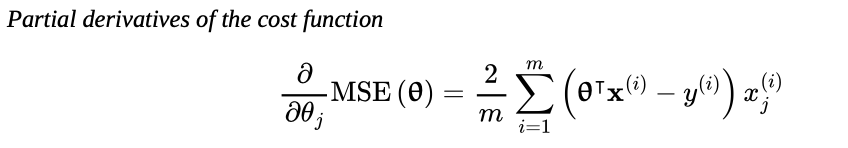

Instead of computing these partial derivatives individually

, we can use `below equation` to compute them all in one go . The gradient vector , denoted ∇θ*MSE(θ) , contains all the partial derivative of cost function (one fore each model parameter).


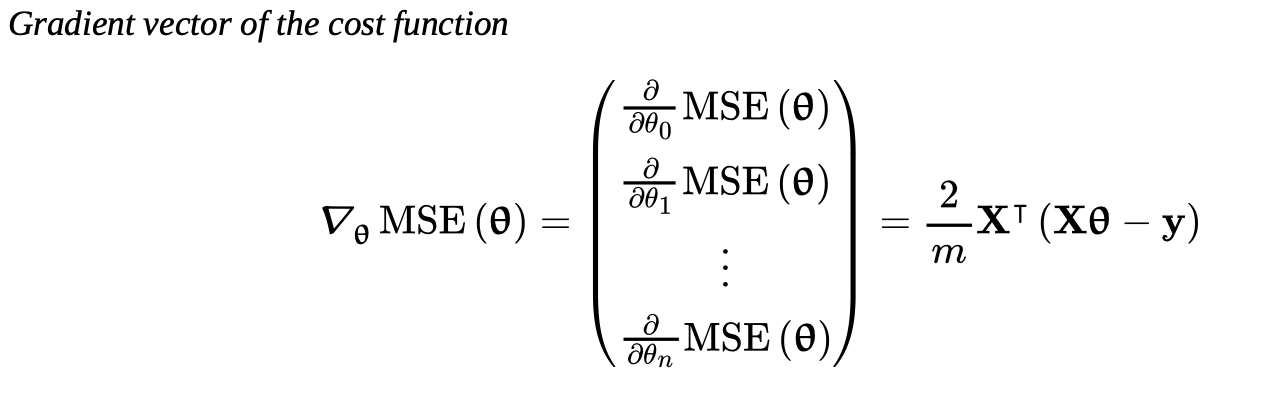

`NOTE`

* this formula involves calculations over full training set X , at each gradient descent step , and because of that this algorithm is called `Batch gradient descent `


`ADV`

* Gradient descent scales well with the
number of features; training a linear regression model when there are hundreds of thousands of features is much
faster using gradient descent than using the normal equation or SVD decomposition.

### 2.3 Gradient descent step

Once you have the gradient vector, which points uphill, just go in the opposite direction to go downhill. This means
subtracting `∇θMSE(θ) from θ.` This is where the `learning rate η` comes into play: multiply the gradient vector by η to
determine the size of the downhill step

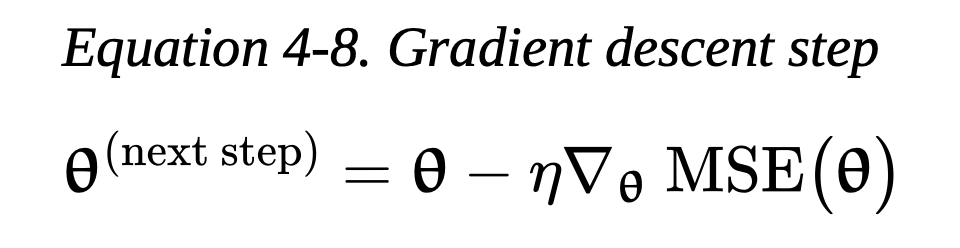

In [ ]:
# Let's code it out (algorithm)
eta = 0.1  # Learning rate
n_epochs = 1000 # setting up no. of epochs
m = len(X_b) # no. of instances

rng = np.random.default_rng(seed = 42)

# s1 - starting up with random guesses for θ₀, θ₁ as (we don't know
# the answer yet, so we start anywhere and improve).
theta = rng.standard_normal((2,1)) # randomly initialized model parameters

# s2 -
for epoch in range(n_epochs):
  gradients = 2 / m * X_b.T @ (X_b @ theta - y)
  theta = theta - eta * gradients


In [ ]:
theta # best theta

array([[3.69084138],
       [3.32960458]])

`Note`

1. To find a good learning rate , we can use `Grid Search`,
but have to limit the no. of epochs so that grid can eliminate models that take too long to converge .

2. For choosing the right epoch -  A
simple solution is to set a very large number of epochs but to interrupt the algorithm when the gradient vector becomes
tiny—that is, when its norm becomes smaller than a tiny number ε (called the tolerance)—because this happens when
gradient descent has (almost) reached the minimum.

## 3.Stochastic Gradient Descent

1. Batch gradient descent is trained on the whole training set , which makes it very slow when the training set is large . But


2. Stochastic Gradient Descent picks a random instance in the training set at every step and computes the gradients based only on that single instance .

`Disadvantage`

3. this algorithm is much less regular than batch gradient descent : instead of gently decreasing until it reaches the minimum, the cost function will bounce up and down, decreasing
only on average. Over time it will end up very close to the minimum, but once it gets there it will continue to bounce
around, never settling down and after algo stops , the final parameter will be good but not optimal .


`Advantage`

4. Ofcourse cost function is very irreregular but this helps algorithm jump out of local minima , so SGD have better chance of finding the global minimum than batch gradient descent

`NOTE`

1. randomness is good to escape the local optima but bad as the algorithm can never settle at the minimum ,but

`ONE SOLUTION`

2. Gradually reduce the learning rate(which helps make quick progress and escape local minima), then get smaller and smaller step , which allows algorithm to settle at global minimum .




`Learning schedule` - The function that determines the learning rate at each iteration

`LEARNING SCHEDULE`

* Instead of using one fixed learning rate for every step , SGD(Stochastic Gradient Descent)
here uses a rate that shrinks over time .

`WHY SHRINKING`

* For early stages , big steps are fine but if it stays same (big steps) then the Q will keep bouncing around near the minimum instead of setlling down

so for example

* t=0 (start): lr = 5/50 = 0.1 (bigger step)
* t=1000: lr = 5/1050 ≈ 0.0048 (tiny step, near end)

In [ ]:
# Implementing stochastic gradient descent using a simple learning schedule

n_epochs = 50
t0 , t1 = 5, 50 # learning schedule hyperparameter

def learning_schedule(t): # defining the learning schedule
  return t0 / (t + t1)

rng = np.random.default_rng(seed = 42)
theta = rng.standard_normal((2,1))

for epoch in range(n_epochs):
  for iteration in range(m):
    random_index = rng.integers(m)
    xi = X_b[random_index : random_index + 1]
    yi = y[random_index : random_index + 1]
    gradients = 2 * xi.T @ (xi @ theta - yi) # for SGD , do not divide by m
    lr = learning_schedule(epoch * m + iteration)
    theta = theta - lr * gradients

In [ ]:
theta # best theta

array([[3.69826475],
       [3.30748311]])

`NOTE`

* Since instances are picked randomly , so some instances may be picked several times per epoch , while few may not be picked at all.

* For us to be wanting that the algorithm goes through every instance at each epoch , another approach is to shuffle to training set , and then go through it instance by instance , then shuffle it again and so on .

`Disadvantage` :- shuffling process for choosing and testing out on more instances is more complex


`WARNING`

When using stochastic gradient descent, the training instances must be `independent and identically distributed (IID)`
to ensure that the parameters get pulled toward the global optimum, on average. A simple way to ensure this is to
shuffle the instances during training (e.g., pick each instance randomly, or shuffle the training set at the beginning of
each epoch). If you do not shuffle the instances—for example, if the instances are sorted by label—then SGD will
start by optimizing for one label, then the next, and so on, and it will not settle close to the global minimum.

`NOTE`

to perform linear regression with SGD in scikit learn then we will be using the SGDRegressor class , which by defaults to optimizing the MSE cost function .



`INFO about CODE`

* `Max_epochs` = 1000 (max_iter) or until the loss drops by less than 10^-5(tolerance) during 100 epochs (n_iter_no_change).
* `learning rate` = 0.0(eta0)
* `Learning schedule` = default
* `Regularization` = No , Not using it where ,(penalty = None)

In [ ]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter = 1000 , eta0 = 0.01,
                       penalty = None , tol = 1e-5 ,n_iter_no_change = 100 ,
                       random_state = 42)

sgd_reg.fit(X, y.ravel()) # y.ravel() because fit expects 1D targets

SGDRegressor(n_iter_no_change=100, penalty=None, random_state=42, tol=1e-05)

In [ ]:
sgd_reg.intercept_ , sgd_reg.coef_

# so , we getting a soltuion which is near to normal equation


(array([3.68899733]), array([3.33054574]))

`TIP`

* All Scikit-Learn estimators can be trained using the fit() method, but some estimators also have a `partial_fit()` method that you can call to run a single round of training on one or more instances (it ignores hyperparameters like max_iter or tol). Repeatedly calling `partial_fit()` will gradually train the model. This
is useful when you need more control over the training process.

* Other models have a `warm
_start` hyperparameter
instead (and some have both): if you set `warm_start=True`, calling the fit() method on a trained model will not
reset the model; it will just continue training where it left off, respecting hyperparameters like max
iter and tol.

`Note`

that `fit()` resets the iteration counter used by the learning schedule, while `partial_fit()` does not.

## 4.Mini-Batch Gradient Descent


* Mini-Batch computes the gradients on small random sets of instances called mini - batches.

* ADV of MB gradient descent over SGD - we can get a performance boost from hardware acceleration of matrix operations , especially when using graphical processing units(GPUs).

Below here

* m , is the no. of trainig instances

* n , is the no. of features

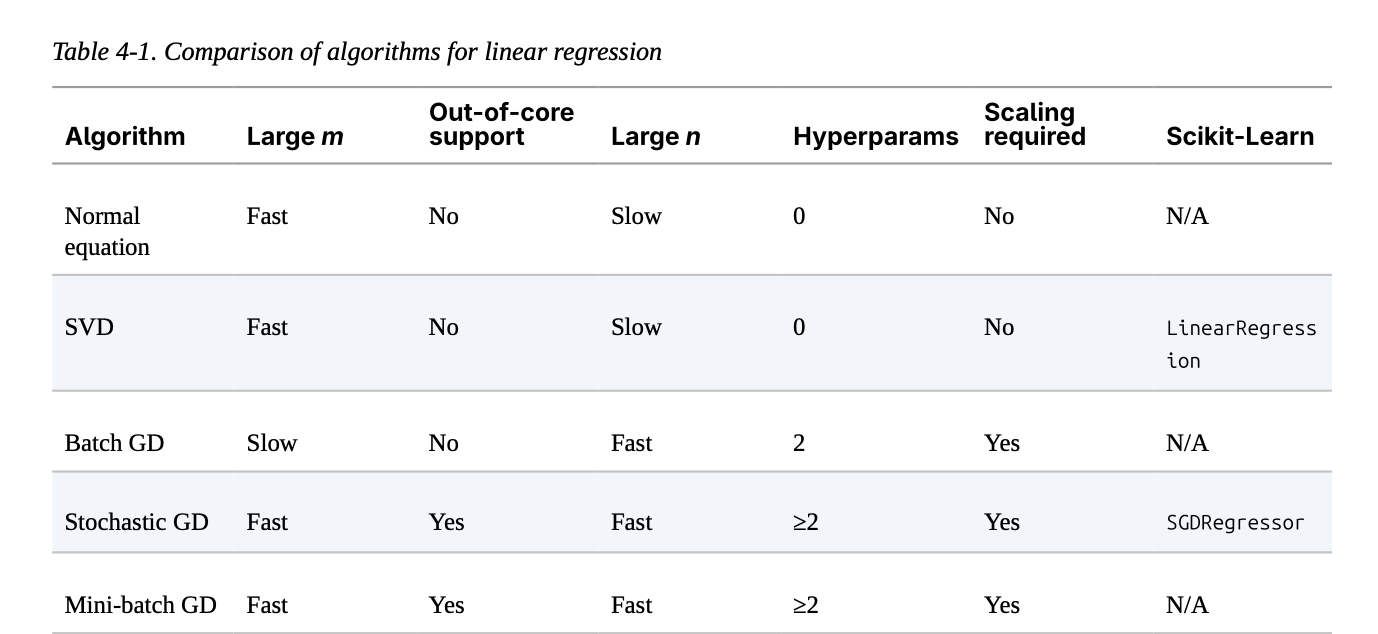

`NOTE`

1. There is almost no difference after training: all these algorithms end up with very similar models and make predictions in exactly the same way .

## 5.Polynomial Features

What if your data is more complex than a straight line ?

`NOTE`
* We can use a linear model to fit nonlinear data . A simple way to do this is to add powers of each feature , This techqnique is called `polynomial regression`


Based on simple quadratic equation - that's an equation of the form y = ax^2 + bx + c - plus some noise

In [ ]:
# generating some non-linear data

rng = np.random.default_rng(seed = 42)
m = 200 # no. of instances
X = 6 * rng.random((m,1)) - 3
y = 0.5 * X ** 2 + X + 2 + rng.standard_normal((m,1))


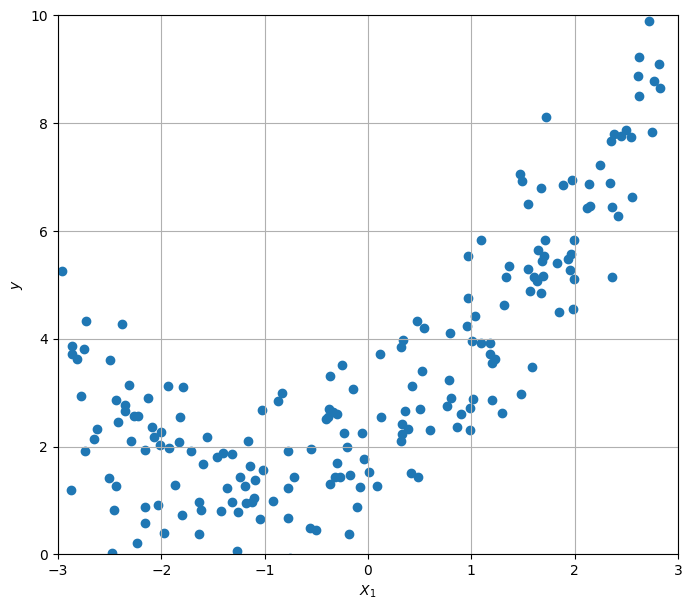

In [ ]:
plt.figure(figsize = (8,7))
plt.scatter(X, y)
plt.ylabel("$y$")
plt.xlabel("$X_1$")
plt.axis([-3,3,0,10])
plt.grid(True)
plt.show()

Clearly , no straight line will fit in this data properly.

Now , we will use Scikit-Learn PolynomialFeatures class
* to transform our trainign data,
* adding the square(second-degree polynomial) of each feature in training set as a new feature,

`Note` :- here we only have one feature

In [ ]:
# Let's add polynomial features ,
# Lets code it out

from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree = 2 , include_bias = False)
poly_features

PolynomialFeatures(include_bias=False)

include_bias = False

* refers to the dummy $x_0$ = 1 column , not the degree-2 transformation itself ,

* dont add an extra 1's column(bias/intercept term) to the output . Just give the polynomial features(x, $x^2$)- skip adding that constant "1" column , since models like LinearRegression already add their own intercept internally .


`Example:` with X = [[2]], degree=2:

* include_bias=True → output: [1, 2, 4] (1=bias, 2=x, 4=x²)
* include_bias=False → output: [2, 4] (just x, x² — no bias column)

In [ ]:
X_poly = poly_features.fit_transform(X)

# X and X_poly values at 0
X[0] , X_poly[0]

(array([1.64373629]), array([1.64373629, 2.701869  ]))

X_ploy now contains the original feature of X plus the square of this feature.

In [ ]:
# now let's fit the a LinearRegression model
# to this extended training data
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_poly , y)

# let's check out the intercept and bias
print(lin_reg.intercept_.round(2))
print(lin_reg.coef_.round(1))

[2.01]
[[1.1 0.5]]


1. `X_new`
* Creation of X_new for smooth curver plotting - why ?  because X is only 200 ranodm scatter points , not evenly ordered, so plotting predictions directly on it would look messy / jagged .

* But X_new will evenly spaced(by using linspace), giving a clean smooth line/curve when predictions are gonna be plotted

2. `X_new_poly`
* we'll be applying the same transformation on X_new (i.e the PolynomialFeature , sqauring) to these new points

* But we will use the `transform()` not `fit_transform()`

3. `y_predict`
* will predict on X_new_poly i.e get predictions for all new x-values , using the trained 0's

In [ ]:
# let''s code it out

X_new = np.linspace(-3,3, 100).reshape(100,1)
X_new_poly = poly_features.transform(X_new)
y_predict = lin_reg.predict(X_new_poly)

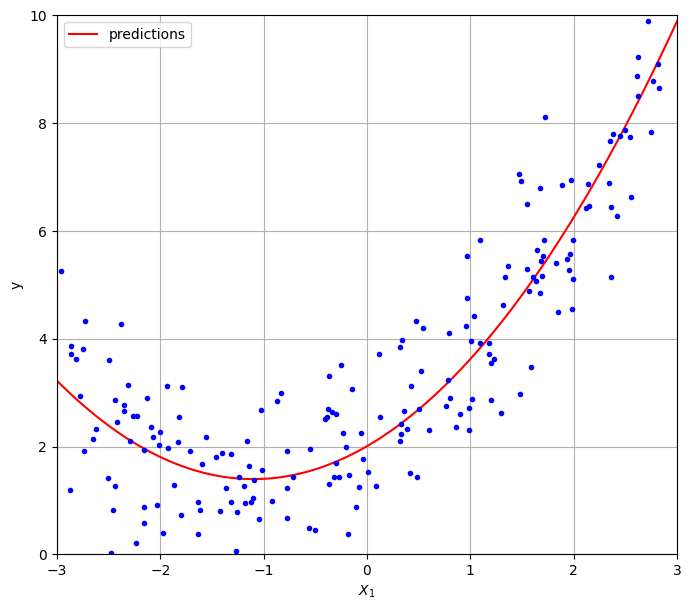

In [ ]:
plt.figure(figsize = (8,7))
plt.plot(X_new, y_predict, "r-" , label = "predictions")
plt.plot(X, y, "b.")
plt.xlabel("$X_1$")
plt.ylabel("y")
plt.grid(True)
plt.axis([-3,3,0,10])
plt.legend()
plt.show()

Here , the model estimates

$ˆy$ = 0.56$x_1^2$ + 0.93$x_1$ + 1.78

when in fact the original function was

 y = 0.5$x_1^2$ + 1.0$x_1$ + 2.0 + Gaussian noise .

NOTE

1. when there are multiple features , polynomial regression is capable of finding relationships between features , which is something a plain  linear regression model can't do

2.  For example, if there were two
features `a`, `b`, PolynomialFeatures with degree=3 would not only add the features $a^2$
, $a^3$
, $b^2$, and $b^3$, but also the
combinations ab, $a^2$b, and $ab^2$
.

## 6.Learning Curves

If You perform high-degree polynomial regression, you will likely fit the training data much better than with plain linear
regression. For example, a 300-degree polynomial model to the preceding training data, and
compares the result with a pure linear model and a quadratic model (second-degree polynomial). Notice how the 300-
degree polynomial model wiggles around to get as close as possible to the training instances.

* To identify what model is overfitting and underfitting the data ?

Use the cross validation to get an estimate of a model's generalization performance .


* Another approach to tell whether model is complex is Learning curves

which are plots of the model’s training error and validation error as a
function of the training iteration: just evaluate the model at regular intervals during training on both the training set and
the validation set, and plot the results. If the model cannot be trained incrementally (i.e., if it does not support
partial_fit() or warm_start), then you must train it several times on gradually larger subsets of the training set.

`NOTE` :- We gonna Scikit-Learn `learning_curve` function,

* Helps - it trains and evaluates the model using cross-validation.

`NOTE` :- If model supports incremental learning , we can set `exploit_incremental_learning = True` :-  it helps with training the model incrementally instead .



`learning_curve()` - returns the training set sizes at which it evaluated the model , and the training and validation scores it measured for each size and for cross-validation fold.

In [ ]:
# lets code it out , and checks the learning curves of plain linear regression model
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LinearRegression

train_sizes , train_scores , valid_scores = learning_curve(
    LinearRegression() , X , y , train_sizes = np.linspace(0.01, 1.0 , 40) ,
    cv = 5 , scoring = "neg_root_mean_squared_error"
)

train_errors = -train_scores.mean(axis = 1)
valid_errors = -valid_scores.mean(axis = 1)

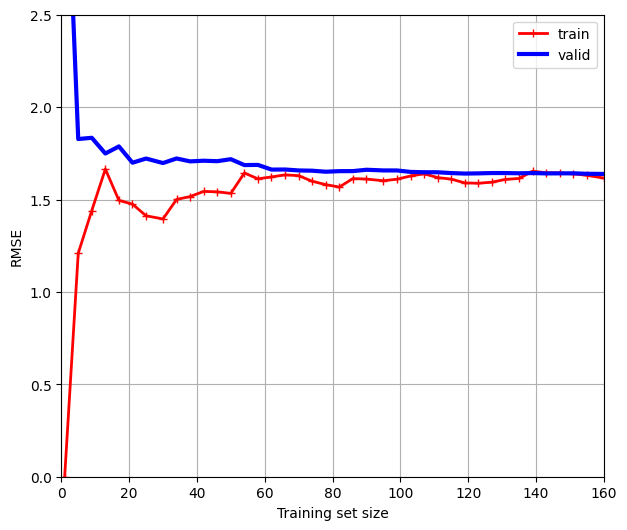

In [ ]:
# Lets plot it
plt.figure(figsize = (7,6))
plt.plot(train_sizes , train_errors, "r-+" , linewidth = 2 , label = "train")
plt.plot(train_sizes , valid_errors, "b-" , linewidth = 3 , label = "valid")
plt.grid(True)
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.legend()
plt.axis([0,160 , 0,2.5])
plt.show()

The model is underfitting , it's too simple for the data .

we can tell by looking at the training error , when there is one or just two instance in the training set , the modle fit them perfectly , and bcoz of that the curve starts at zero .

`NOTE` :-  When  new instances are added to the training set, it becomes impossible for the model to fit the training data perfectly,
both because the data is noisy and because it is not linear at all. So the error on the training data goes up until it reaches a
plateau, at which point adding new instances to the training set doesn’t make the average error much better or worse.
Now let’s look at the validation error. When the model is trained on very few training instances, it is incapable of
generalizing properly, which is why the validation error is initially quite large. Then, as the model is shown more training
examples, it learns, and thus the validation error slowly goes down. However, once again a straight line cannot do a good
job of modeling the data, so the error ends up at a plateau, very close to the other curve.

`TIP`

If your model is underfitting the training data, adding more training examples will not help. You need to use a better
model or come up with better features.

In [ ]:
# looking at the learning curve of a 10th-degree polynomial model on the same data
from sklearn.pipeline import make_pipeline

polynomial_regression = make_pipeline (
    PolynomialFeatures(degree = 10, include_bias = False),
    LinearRegression())

train_sizes , train_scores , valid_scores = learning_curve(
    polynomial_regression, X , y , train_sizes = np.linspace(0.01, 1.0, 40),
    cv = 5 , scoring = "neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

here it did overfititng now big gap between errors

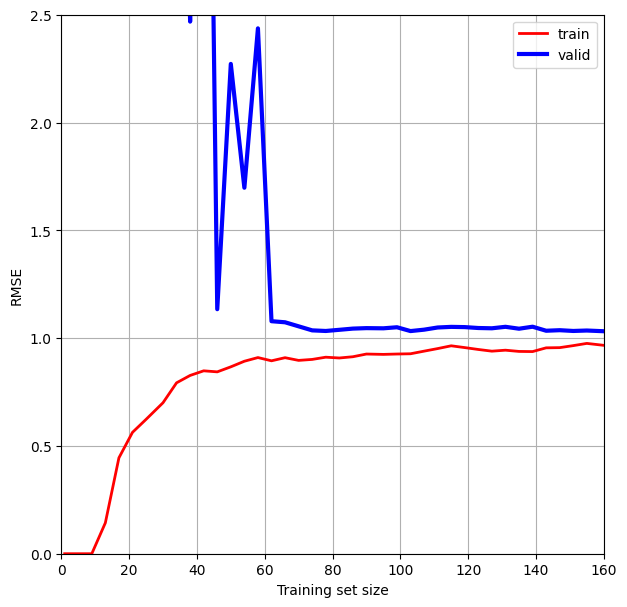

In [ ]:
plt.figure(figsize = (7,7))
plt.plot(train_sizes , train_errors , "r-" , linewidth = 2 , label = "train")
plt.plot(train_sizes , valid_errors, "b-" , linewidth = 3 , label = "valid")
plt.grid(True)
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.axis([0,160,0,2.5])
plt.legend()
plt.show()

NOTE:- the error on the trianing dat is much lower than before

there is a gap between the curves . This means the model performs beteer on the training data than on the validation data , which is the hallmark of an overfitting model . If you used a much larger trainign set , however, the two curves would continue to get closer.

Learning curve concept (short): plot train error vs validation error as training set size grows. Shape tells you model complexity issues:

* `Underfitting` (too simple): both train & valid errors are high and close together, plateau quickly.
* `Overfitting` (too complex): train error very low, valid error much higher — big gap between them.

Returns
1. train_sizes — actual number of instances used at each step.
2. train_scores — RMSE on training data (shape: 40 sizes × 5 folds).
3. valid_scores — RMSE on validation/held-out data (same shape).

-train_scores.mean(axis=1) — average across the 5 folds (axis=1) to get one error value per size; negate since scoring="neg_root_mean_squared_error" returns negative values (sklearn convention — higher score = better, so error is stored negative).

## 7.The BIAS/VARIANCE TRADE-OFF

`TBR` - Model's generalization error  = sum of three different errors



1. `Bias` - The error is created due to wrong assumptions

Eg :- Assuming that the data is $linear$ when it is actually quadratic. A high-bias model is most likely to underfit the training data .

2. `Vairance` - The errors is due to the model's excessive sensitivity to small variations in the training data.

Eg:- A model with many degrees of freedom(such as a high-degree polynomial model) is likely to have high variance and thus overfit the training data.

3. `Irreducible error` - This part is due to the noisiness of the data itself .

AND

the only way to reduce this part of the error is to clean up the data.


Eg:- fix the data sources, such as broken sensors or detect and remove the outliers.


`TBR`

* Increasing the model's complexity will inrease it's $Variance$ and reduce it's $Bias$ . and then vice versa.

And this all is called  a Trade-off.



TIP:-

1. If wants to improve an overfitting model is to feed it more training data until the validation error gets close enough to the training error.

## 8.Regularized Linear Model

The the fewer degrees of freedom model has , harder it will be for it to overfit the data

To regularize a polynomial model  is to reduce the no. of polynomial degrees.

To regularize a linear model can be done by constraining its weights , three ways:-

1. Ridge Regression
2. Lassso Regression
3. Elastic net Regression


### 8.1 Ridge Regression(Tikhonov regularization)

It's a regualarized version of linear regression: a regularization term equal to



$alpha/m$ $*$ $∑^n_i=1$ $θi^2$

and is added to the MSE . This forces the learning algorithm to
* fit the data ,
* keep model weights as small as possible .
results in reducing the overfitting risks

`MUST`

only allowd to add the regularization term to the cost function during the training


AFTER the model is trained use the unregualrized MSE(or the RMSE). to evaluate the model's performance

SOME TIPS:-

* The hyperparameter α controls how much you want to regularize the model.

1. If α = 0, then ridge regression is just linear
regression.

2. If α is very large, then all weights end up very close to zero and the result is a flat line going through the
data’s mean.

`Ridge regression cost function` Below

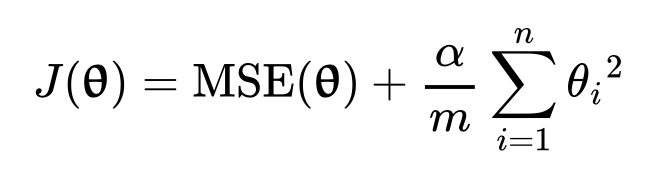

ALWAYS remember it is important to scale the data(e.g., using a StanadardScaler) before performing ridge regression , as it is sensitive to the scale of the innout features . This is true of most regualarized models .

####8.1.1 let's see the code

As with linear regression, we can perform ridge regression either by computing a closed-form equation or by performing
gradient descent

Ridge regression closed-form solution

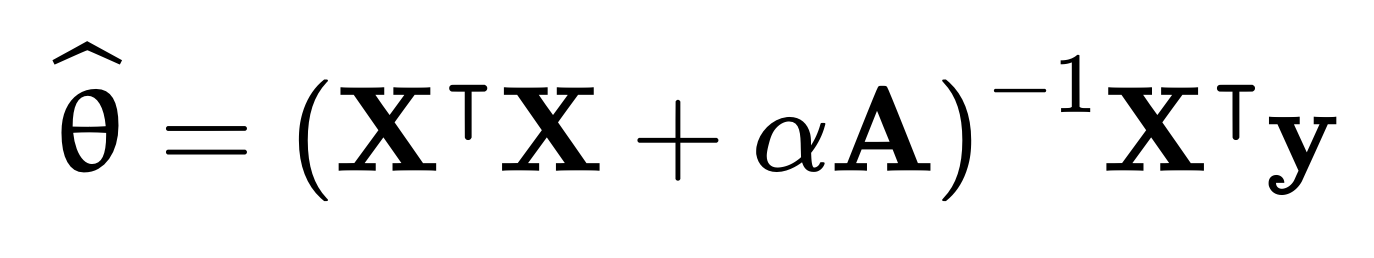

where A is the (n + 1) ×
1
(n + 1) identity matrix,⁠
0 except with a 0 in the top-left cell, corresponding to the bias term.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha= 0.1 , solver ="cholesky")
ridge_reg.fit(X,y)
ridge_reg

# alpha controls regularization strength
# Higher alpha means more shrinkage
# solver="cholesky" — the math method used to compute the solution (closed-form, like Normal Equation).

Ridge(alpha=0.1, solver='cholesky')

In [ ]:
ridge_reg.predict([[1.5]])

array([5.06157854])

####8.1.2 Let's use the stochastic gradient descent


now let's repeat using SGDRegressor with penalty="l2" — same Ridge concept, but solved iteratively (gradient descent) instead of the closed-form solver. Both give nearly the same prediction (≈5.06) — confirming both methods converge to the same answer.

In [ ]:
sgd_reg = SGDRegressor(penalty = "l2" , alpha = 0.1/m , tol = None,
                       max_iter = 1000 , eta0 = 0.01 , random_state = 42)

sgd_reg.fit(X,y.ravel())

sgd_reg

SGDRegressor(alpha=0.0005, random_state=42, tol=None)

* `tol` — tolerance for stopping; if improvement between iterations is smaller than tol, training stops early (considered "converged"). tol=None → just runs full max_iter iterations, no early stopping based on improvement.

* `penalty` — which type of regularization to apply:

1. `"l2"` → Ridge-style (penalize sum of squared weights)
2. `"l1"` → Lasso-style (penalize sum of absolute weights)
3. `None` → no regularization

* `alpha` — regularization strength (how much to penalize large weights). Higher = more shrinkage/simpler model. alpha=0 = no regularization effect.

In [ ]:
sgd_reg.predict([[1.5]])

array([5.06208065])

### 8.2 Lasso Regreesion

What is it :-
Least absolute shrinkage and selection operator regression (usually simply called lasso regression) is another regularized
version of linear regression

Difference B/W Ridge regression and Lasso regression

* Lasso uses the $l_1$ norm of the weight vector instead of the square of the $l_2$ norm .

* Here $l_1$ norm is multiplied by 2α , but in Ridge regression $l_2$ norm is multiplied by α/m is ridge regression .



Characteristics


An important characteristic of lasso regression is that it tends to eliminate the weights of the least important features (i.e.,
set them to zero)

NOTE:- if
you increase α too much, the model will be very sparse, but its performance will plummet.

Lasso Regression cost function

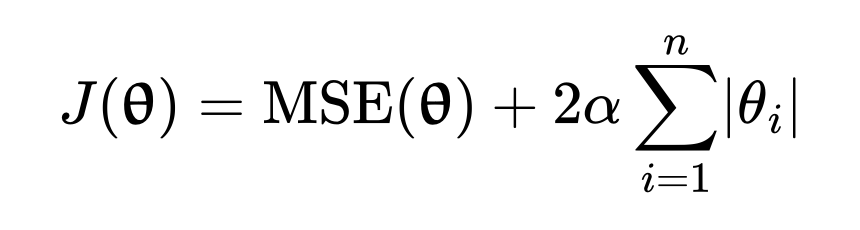

`TIP`

To keep gradient descent from bouncing around the optimum at the end when using lasso regression, you need to
gradually reduce the learning rate during training. It will still bounce around the optimum, but the steps will get
smaller and smaller, so it will converge.

The lasso cost function is not differentiable at θi = 0 (for i = 1, 2, ⋯ n ), but gradient descent still works if you use a subgradient vector g⁠^12 instead when any θi = 0. below equation  shows a subgradient vector equation you can use for
gradient descent with the lasso cost function.

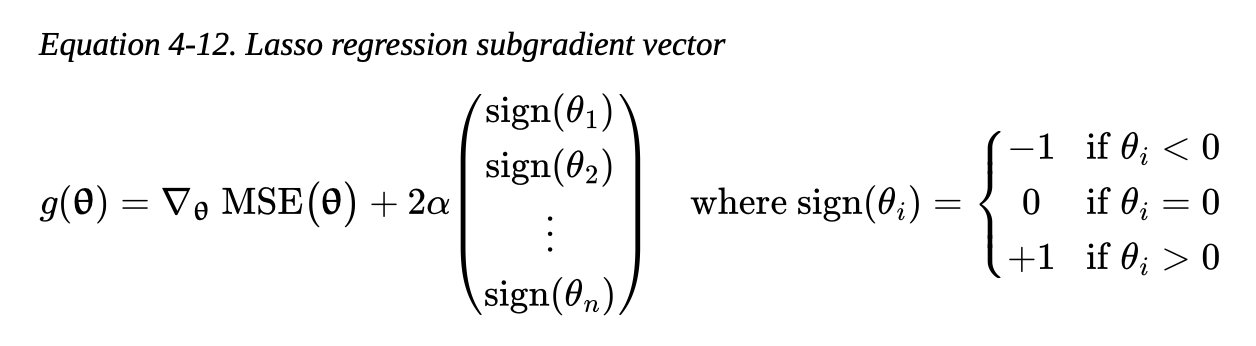

#### 8.2.1 Let's see the example code

In [ ]:
from sklearn.linear_model import Lasso
lasso_reg = Lasso(alpha = 0.1)
lasso_reg.fit(X,y)
lasso_reg

Lasso(alpha=0.1)

In [ ]:
lasso_reg.predict([[1.5]])

array([5.00803756])

#### 8.2.2 Testing on SGDRegressor code

In [ ]:
from sklearn.linear_model import SGDRegressor

sgd_reg2 = SGDRegressor(penalty = "l1" , alpha = 0.1 , tol = None,
                       max_iter = 1000 , eta0 = 0.01 , random_state = 42)

sgd_reg2.fit(X,y.ravel())
sgd_reg2


SGDRegressor(alpha=0.1, penalty='l1', random_state=42, tol=None)

In [ ]:
# Predicting on the same X we did on lasso regression
sgd_reg2.predict([[1.5]])

array([5.00855452])

### 8.3 Elastic Net Regression

Elastic net regression is a middle ground between ridge regression and lasso regression .

Here , the regularization term is the sum of both ridge and lasso's regularization terms ,
also can control the mix ratio r.


1. When r = 0 , elastic net is equivalent to ridge regression
2. when r = 1 , it is equivalent to lasso regression







Equation $->$   `Elastic net cost function`.



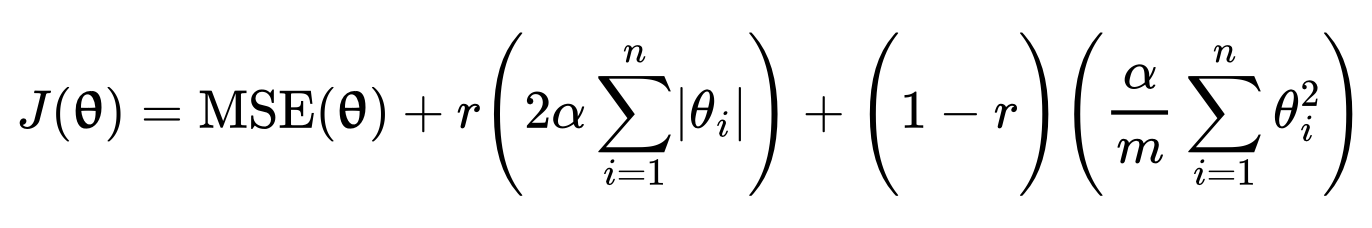

Regularization is always prefered so ,

* To choose B/w elastic net regression, or ridge, lasso, or plain linear regression ,

1. Ridge - as a good default

2. Lasso or Elastic net -  if suspect that only a few features are useful
* as they help to reduce to useless features `weights down to Zero`


`NOTE` :- Usually Elastic net is preferred over lasso because lasso may behave erratically when the number of features is greater than the number oftraining instances or when several features are strongly correlated.

Short example using Scikit-learn's ElasticNet
$l_1$ ratio corresponds to the mix ratio r

In [ ]:
from sklearn.linear_model import ElasticNet
elastic_net = ElasticNet(alpha = 0.1 , l1_ratio = 0.5 )
elastic_net.fit(X,y)

elastic_net

ElasticNet(alpha=0.1)

In [ ]:
elastic_net.predict([[1.5]])

array([5.006944])

### 9.Early stopping

A different way to regularize iterative learning algorithms such as gradient descent is to stop training as soon as the
validation error reaches a minimum


E.g:- a complex model is being trained(using high - degree polynomial regression model) being trained with batch gradient descent on the quadratic dataset we used earlier . So epochs go by and the prediction error decreases on the training set and also decreases on the validation set , but now after a while it starts increasing so that means overfitting happening so stop there training

The validation error sometimes comes back down after
a while: this is called double descent.

Uses - common with large neural networks, and is an area of active research

`Process`

This code first adds the polynomial features and scales all the input features, both for the training set and for the
validation set (the code assumes that you have split the original training set into a smaller training set and a validation
set). Then it creates an SGDRegressor model with no regularization and a small learning rate. In the training loop, it
calls partial
_
fit() instead of fit(), to perform incremental learning. At each epoch, it measures the RMSE on the
validation set. If it is lower than the lowest RMSE seen so far, it saves a copy of the model in the best
model variable.
_
This implementation does not actually stop training, but it lets you revert to the best model after training.

In [ ]:
# let's code it out
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
m = 100
X = 6 * np.random.rand(m,1) - 3 # random values after 6* -> [0,6) then -3 means -> [-3,3)
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m,1)
#

print(f"length of the instances : {len(X)}")
print(f"length of the outputs/results : {len(y)}")

X.shape , y.shape


length of the instances : 100
length of the outputs/results : 100


((100, 1), (100, 1))

y is the qudratic eq

$0.5x^2$ + x + 2 + np.random.randn(m,1)

{for adding gaussian noise , mean 0 and SD 1 , so the points scatter around the curve}

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

X_train , y_train = X[:m // 2] , y[:m // 2 , 0] # split into first half (50) instances
X_valid , y_valid = X[m //2: ], y[m // 2 :, 0]# same rest half/ second half 50  instances for validation

preprocessing = make_pipeline (PolynomialFeatures(degree = 90, include_bias = False),
                               StandardScaler())
# degree = 90 so model overfit and StandardScale scales the features so gradient descent behaves

In [ ]:
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)

preprocessing

Pipeline(steps=[('polynomialfeatures',
                 PolynomialFeatures(degree=90, include_bias=False)),
                ('standardscaler', StandardScaler())])

In [ ]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(penalty = None , eta0 = 0.002, random_state = 42)
# no regualrization as penalty = None

n_epochs = 500 # no. of epochs
best_valid_rmse = float('inf') # inf = infinity ,

# for stopping - extra code
patience = 20
no_improve = 0

for epoch in range(n_epochs):
  sgd_reg.partial_fit(X_train_prep, y_train)
  # trains one epoch at a time (fit would run everythign at once).

  y_valid_predict = sgd_reg.predict(X_valid_prep)
  val_error = root_mean_squared_error(y_valid , y_valid_predict)

  if val_error < best_valid_rmse:
    best_valid_rmse = val_error
    best_model = deepcopy(sgd_reg)
    best_epoch = epoch
# extra code adding the patience so that we can tell model when
# to stop if there is no improvment in error , otherwise the model is
# running till 500 epochs
  else :
    no_improve += 1
    if no_improve >= patience:
      break


`best_valid_rmse = float.('inf)`


We need a starting value for "best error so far" before any epoch has run. Setting it to infinity guarantees the first real validation error is smaller, so if val_error < best_valid_rmse is true on epoch 1 and the model gets saved.

from then on, best_valid_rmse only updates when a new error is lower, so it always holds the lowest error seen

Example:

* start: best = inf
1. epoch 1: error 5.0 → 5.0 < inf ✓ → best = 5.0
2. epoch 2: error 3.2 → 3.2 < 5.0 ✓ → best = 3.2
3. epoch 3: error 4.1 → 4.1 < 3.2 ✗ → no update

`Note`

1. Each epoch : predict on validation -> computes RMSE -> if it's nww low , save best_model

In [ ]:
print(best_valid_rmse) # lowest validation RMSE error

1.4099344710854789


In [ ]:
print(best_model)

SGDRegressor(eta0=0.002, penalty=None, random_state=42)


In [ ]:
print(best_epoch)

249


Terms:

1. Epoch = one full pass over the training data.
2. Parameters = θ values the model learns by itself.
3. Hyperparameters = settings you choose: eta0 (learning rate), n_epochs, patience, degree.

## 10.Logistic Regression

some regression algorithms can be used for classification (and vice versa). Logistic regression
(also called logit regression) is commonly used to estimate the probability that an instance belongs to a particular class

Example :- what is the probability that this email is spam?

If the estimated probability is greater than a given threshold
(typically 50%), then the model predicts that the instance belongs to that class (called the positive class, labeled “1”), and
otherwise it predicts that it does not (i.e., it belongs to the negative class, labeled “0”). This makes it a binary classifie

Working:-

Just like a linear regression model, a logistic regression model computes a
`weighted sum of the input features (plus a bias term)`, but instead of outputting the result directly like the linear regression
model does, `it outputs the logistic of this result`

Equation $->$ Logistic regression model estimated probability (vectorized form)

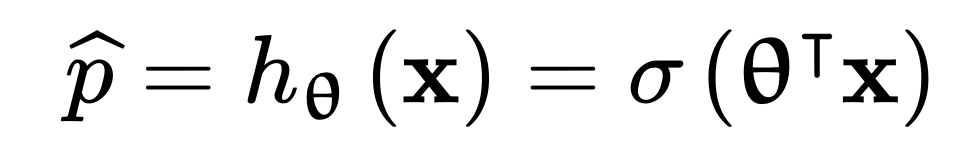

The logistic—denoted `σ(·)`—is a `sigmoid function` (i.e., S-shaped)

1. it ouputs a no. B/w 0 and

defined as :-  

`Logitic Function`



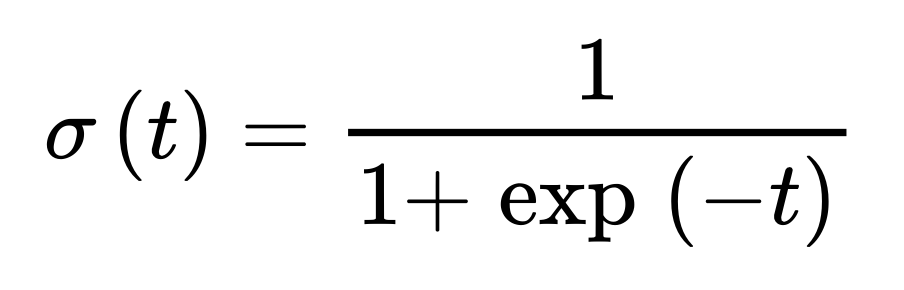

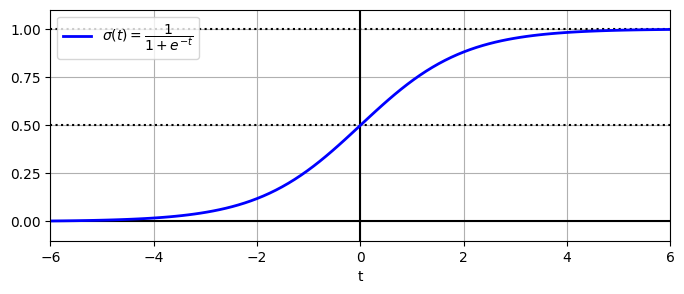

In [ ]:
# extra code – generates and saves Figure 4–21
# just to show the sigmoid function graph. how it looks like


lim = 6
t = np.linspace(-lim, lim, 100)
sig = 1 / (1 + np.exp(-t))

plt.figure(figsize=(8, 3))
plt.plot([-lim, lim], [0, 0], "k-")
plt.plot([-lim, lim], [0.5, 0.5], "k:")
plt.plot([-lim, lim], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \dfrac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left")
plt.axis([-lim, lim, -0.1, 1.1])
plt.gca().set_yticks([0, 0.25, 0.5, 0.75, 1])
plt.grid()
plt.show()

TBR -


Once the logistic regression model has estimated the probability $ˆ p$ = $h_θ$(x) that an instance x belongs to the positive class,
it can make its prediction ŷ easily


`They predict like this ->`

Logistic regression model prediction using 50 % threshold probability

Here-
σ(t) < 0.5 when t < 0, and σ(t) ≥ 0.5 when t ≥ 0,

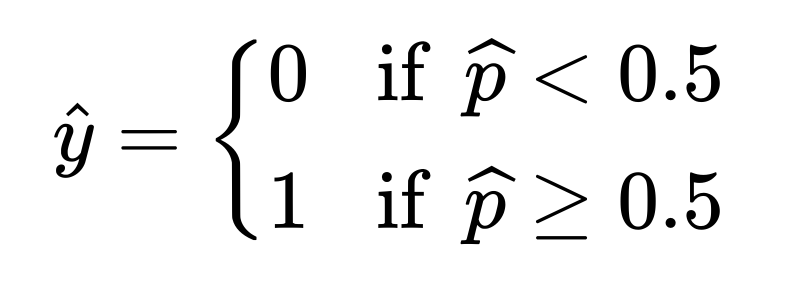

the logit function is the inverse of the logistic function, and t is the output of the logit (which is why t itself is called "the logit" or log-odds).

### 10.1 Training and Cost function

The objective of training is to set the parameter vector θ so that the model estimates high probability for positivre instances  and low probilities for negative instances . This idea is captured by cost function

eqution - cost function of a single training instance

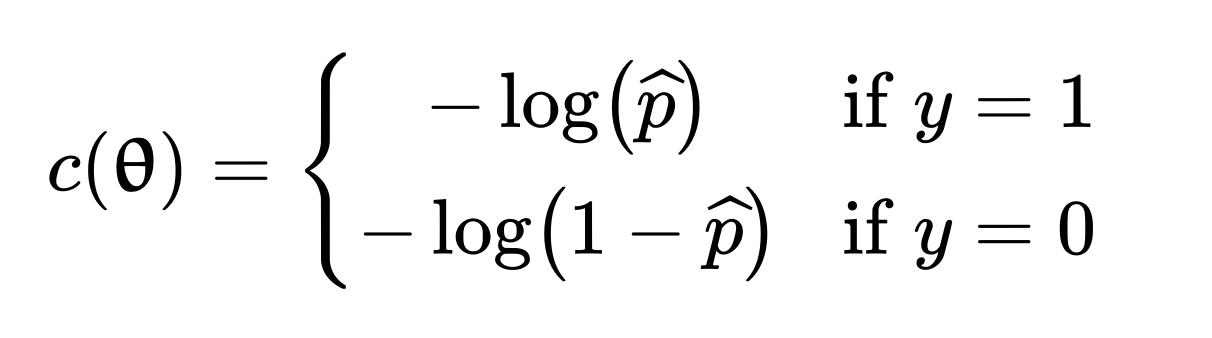

This cost function makes sense because –log(t) grows very large when t approaches 0, so the cost will be large if the
model estimates a probability close to 0 for a positive instance, and it will also be large if the model estimates a
probability close to 1 for a negative instance. On the other hand, –log(t) is close to 0 when t is close to 1, so the cost will
be close to 0 if the estimated probability is close to 0 for a negative instance or close to 1 for a positive instance, which is
precisely what we want.

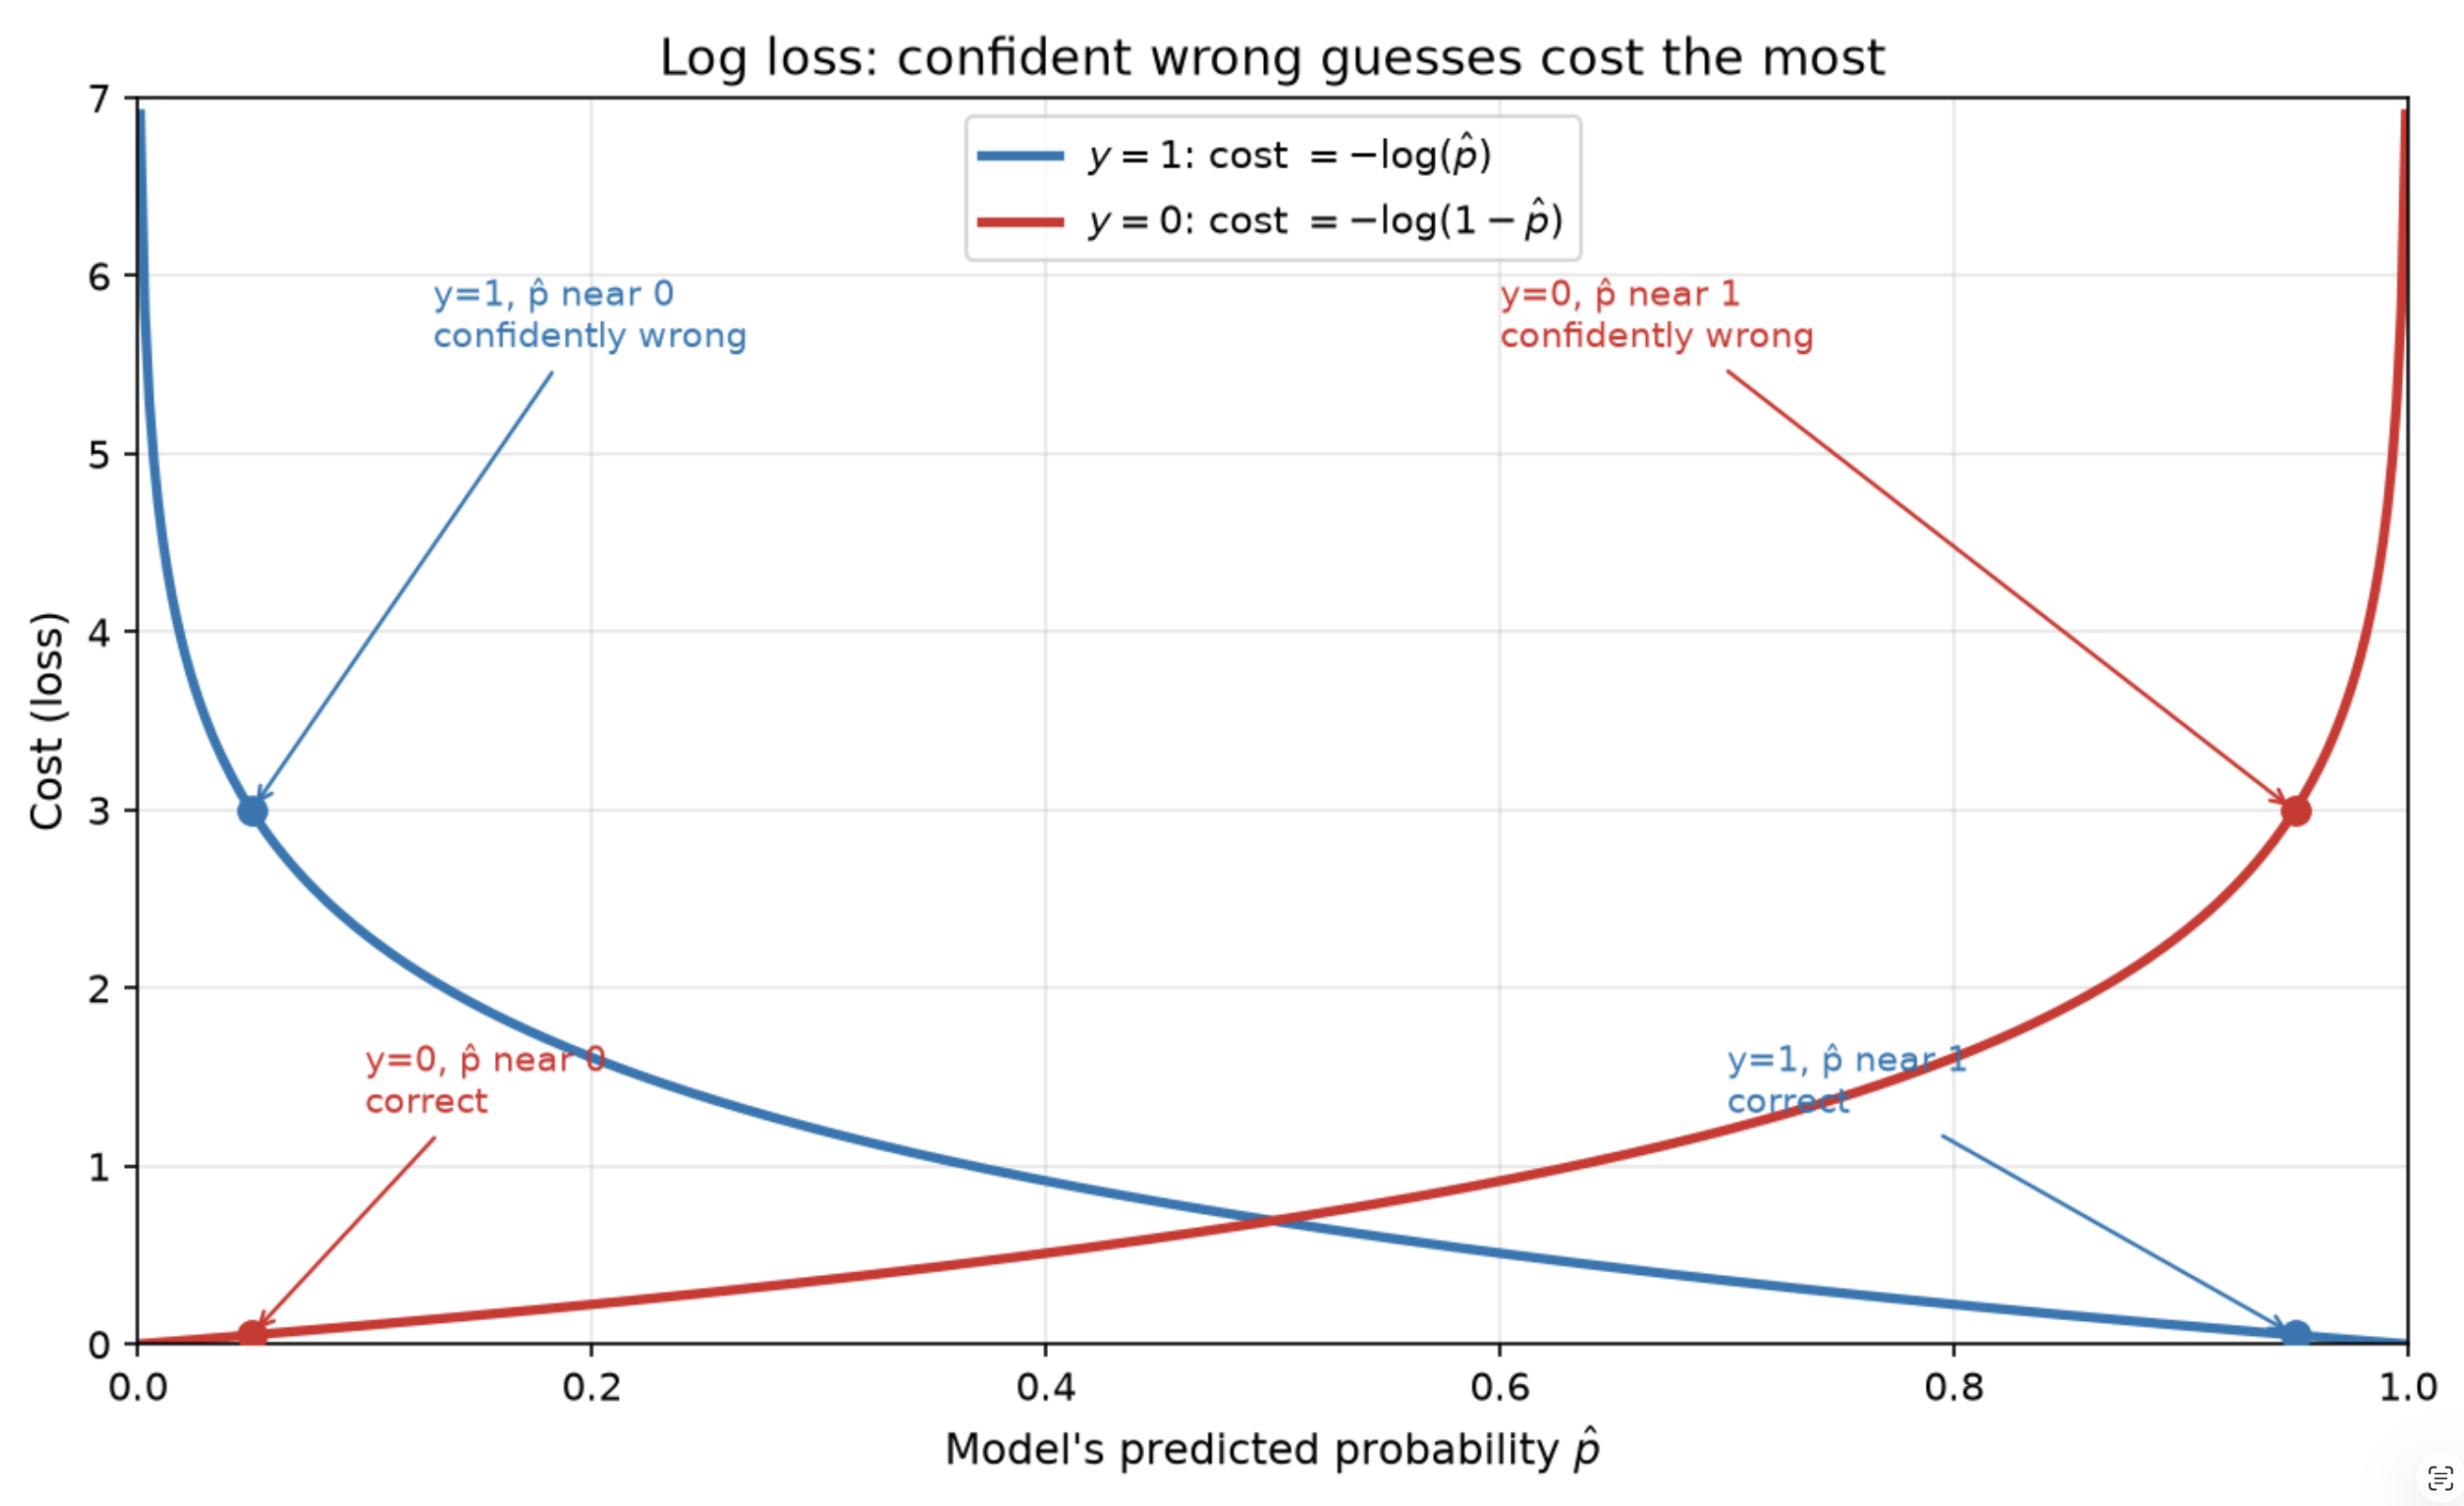

TBR-

Log loss = it's the average of the all the training instance cost and that's what makes the cost function .



It can be wrriten as :       

Logistic regression cost function(log loss)

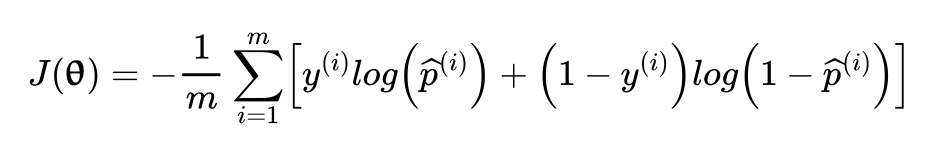

Keep in mind -> that there is no known closed-form equation  to compute the value of $\theta$ that minimizes this cost function , i.e nothing is equivalent to normal equation , but


this cost function is convex , so gradient descent is gauranteed to find the global minimum


The partial derivatives of the cost function with regard to the $j^th$ model parameter $\theta_j$ are given by




```
Logistic cost function partial derivatives
```




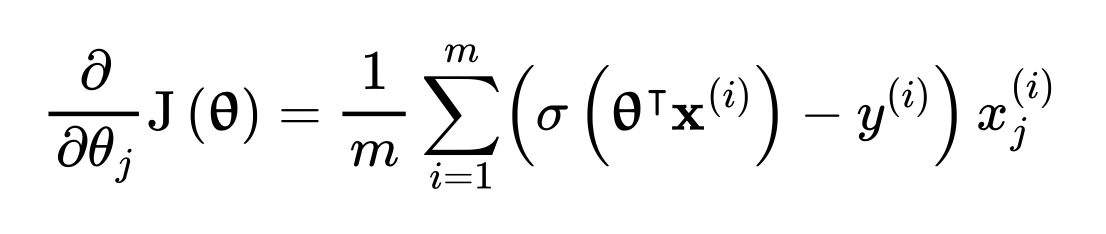

for each instance it computes the prediction error and multiplies it by
the jth feature value, and then it computes the average over all training instances. Once you have the gradient vector
containing all the partial derivatives, you can use it in the batch gradient descent algorithm

### 10.2 Decision Boundaries

Dataset we gonna work on now , its a iris(flower) dataset to illustrate logistic regression .

Dataset contains
1. sepal and petal length
2. width of 150 iris flowers , of three different species ,

* Such as Iris setosa , Iris versicolor and Iris virginica

Building a classifier to detect the Iris virginica type based only on the petal width feature.



In [ ]:
# Load the data
from sklearn.datasets import load_iris
iris = load_iris(as_frame = True)

list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [ ]:
iris.data.head(4)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2


In [ ]:
iris.target.unique()

array([0, 1, 2])

In [ ]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

Next up is splitting

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# for now only choosing one feature
X = iris.data[["petal width (cm)"]].values
# here in X we can pick any feature but we choose this petal width

y = iris.target_names[iris.target] == 'virginica'

# lets create the splits
X_train , X_test , y_train , y_test = train_test_split(X,y, random_state = 42)

# instance creation using LR algorithm
log_reg = LogisticRegression(random_state = 42)

# providing the data for learning
log_reg.fit(X_train,  y_train)

LogisticRegression(random_state=42)

Now Looking at the model's probabilities

```
for flower with petal widths varying from 0 to 3 cm
```



X_new - is a made-up, evenly spaced ruler of 1000 petal widths from 0 to 3. It’s for probing the model: seeing how the probability changes smoothly, and drawing the S-curve.

X_test is scattered, unordered real data. It’s for measuring accuracy (how good the model is)

In [ ]:
# for that let's code it out

X_new = np.linspace(0,3,1000).reshape(-1,1) # reshaping to get a column vector
y_proba = log_reg.predict_proba(X_new)

decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

decision_boundary.round(2)

np.float64(1.65)

`NOTE`

Here the `decision boundary` is the `input` where the probability crosses 0.5 and here it is at 1.64 petal width and any petal width below that will be considered as not virginica

In [ ]:
# To make sure what written above is true let's check
# the probability at the point 1.65
log_reg.predict_proba([[1.65]]).round(2)

array([[0.5, 0.5]])

1. y_proba[:, 1] takes the virginica probability for all 1000 points.

2. `>= 0.5` gives True/False per point. It’s False for small widths and True once the probability crosses 0.5.

3. X_new[that] keeps only the widths where the model says “virginica”. They’re in increasing order, because linspace is ordered.
4. [0, 0] takes row 0, column 0: the smallest width where the probability reaches 0.5. That’s the boundary.

`np.linspace` - makes a list of numbers that are equally spaced between two point

np.linspace(start, stop , number) makes number evenly spaced numbers from start to stop (stop included).

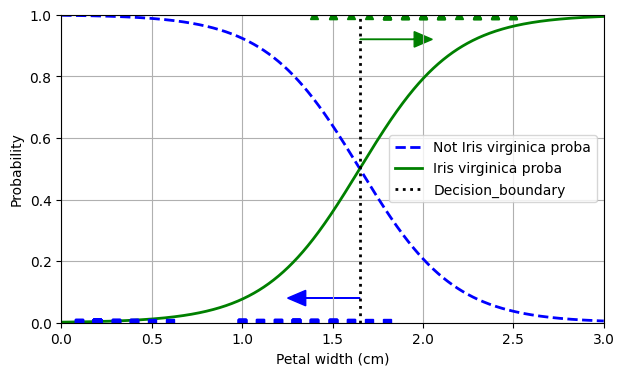

In [ ]:
# Now let's plot the graph
# [:, 0] means all rows and first column
plt.figure(figsize = (7,4))

plt.plot(X_new, y_proba[:, 0], "b--", linewidth = 2 ,
         label = "Not Iris virginica proba")

plt.plot(X_new , y_proba [:, 1] , "g-" , linewidth = 2 ,
         label = "Iris virginica proba")

plt.plot([decision_boundary , decision_boundary], [0,1], "k:" , linewidth = 2,
         label = "Decision_boundary")

# extra code – this section beautifies
plt.arrow(x=decision_boundary, y=0.08, dx=-0.3, dy=0,
          head_width=0.05, head_length=0.1, fc="b", ec="b")
plt.arrow(x=decision_boundary, y=0.92, dx=0.3, dy=0,
          head_width=0.05, head_length=0.1, fc="g", ec="g")
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bs")
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "g^")

# continue code
plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.grid(True)
plt.axis([0.0, 3.0 , 0.0, 1.0])
plt.legend()
plt.show()


In [ ]:
decision_boundary.round(2)

np.float64(1.65)

In [ ]:
log_reg.predict([[1.7], [1.4]])

array([ True, False])

`NOW` here below

this time displaying two features: petal width and length. Once trained, the
logistic regression classifier can, based on these two features, estimate the probability that a new flower is an Iris
virginica. The dashed line represents the points where the model estimates a 50% probability: this is the model’s decision
1
boundary. Note that it is a linear boundary.⁠
6 Each parallel line represents the points where the model outputs a specific
probability, from 15% (bottom left) to 90% (top right). All the flowers beyond the top-right line have over a 90% chance
of being Iris virginica, according to the model.

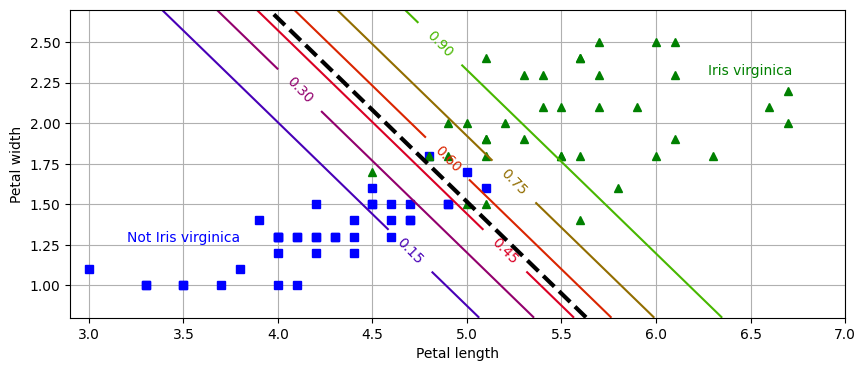

In [ ]:
# extra code – this cell generates and saves Figure 4–24

X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg = LogisticRegression(C=2, random_state=42)
log_reg.fit(X_train, y_train)

# for the contour plot
x0, x1 = np.meshgrid(np.linspace(2.9, 7, 500).reshape(-1, 1),
                     np.linspace(0.8, 2.7, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]  # one instance per point on the figure
y_proba = log_reg.predict_proba(X_new)
zz = y_proba[:, 1].reshape(x0.shape)

# for the decision boundary
left_right = np.array([2.9, 7])
boundary = -((log_reg.coef_[0, 0] * left_right + log_reg.intercept_[0])
             / log_reg.coef_[0, 1])

plt.figure(figsize=(10, 4))
plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], "bs")
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], "g^")
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)
plt.clabel(contour, inline=1)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.27, "Not Iris virginica", color="b", ha="center")
plt.text(6.5, 2.3, "Iris virginica", color="g", ha="center")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.axis([2.9, 7, 0.8, 2.7])
plt.grid()

plt.show()

`NOTE`

* just like the other linear models, logistic regression models can be regularized using ℓ1 or ℓ2 penalties. Scikit-Learn
actually adds an ℓ2 penalty by default.

* The hyperparameter controlling the regularization strength of a Scikit-Learn LogisticRegression model is not
alpha (as in other linear models), but its inverse: C. The higher the value of C, the less the model is regularized.

### 10.3 Softmax Regression

The logistic regression model can be generalized to support multiple classes directly, without having to train and combine
multiple binary classifiers

This is called softmax regression, or multinomial logistic
regression.

`FORMULA`

$S_k$ (x) = $\theta_k ^ T$ * x


* $S_k$(x) the score of class k for instance x
* x - feature vector of one instance (with x₀ = 1 for the bias)
, is the value on which we  want to check which class it belongs to
* k - class index (1, 2, ..., K) ,

is the classes and each class get its own
 $\theta_k$  = weight , so we get one score per class

Result:

```
 one score per class. Softmax then turns the scores into probabilities
```



Note that each class has its own dedicated parameter vector θ(k). All these vectors are typically stored as rows in a
parameter matrix Θ.

Steps

1. Once computed the score of every class for the instance x, you can estimate the probability $ˆ(pk)$ that the instance
belongs to class k by running the scores through the softmax function

2. Then the function computes the
exponential of every score.

3. Then normalizes them (dividing by the sum of all the exponentials).

4. The scores are generally
called logits or log-odds (although they are actually unnormalized log-odds).
)

#### 10.3.1 Softmax function



$$
\hat{p}_k = \sigma(\mathbf{s}(\mathbf{x}))_k = \frac{\exp\left(s_k(\mathbf{x})\right)}{\sum_{j=1}^{K} \exp\left(s_j(\mathbf{x})\right)}
$$

HERE - In this equation :    

1. `K` is the no. of classes
2. s(x) is a vector containing the scores of each class for the instance x .
3. $σ(s(x))_k$ is the estimated probability that the instance x belongs to class k , given the scores of each class for that instance.



`HERE`

* like logistic regression classifier , by default `softmax regression classifier` predicts the class with the `highest estimated probability` i.e the class with the `highest score`

#### 10.3.2 Softmax regression classifier prediction


$$
\hat{y} = \underset{k}{\operatorname{argmax}} \; \sigma(\mathbf{s}(\mathbf{x}))_k = \underset{k}{\operatorname{argmax}} \; s_k(\mathbf{x}) = \underset{k}{\operatorname{argmax}} \; \left( \left( \boldsymbol{\theta}^{(k)} \right)^{\top} \mathbf{x} \right)
$$

* The equation says three things are equal:

1. argmax σ(s(x))ₖ: pick the class with the highest softmax probability.
2. argmax sₖ(x): pick the class with the highest score.
3. argmax (θ⁽ᵏ⁾)ᵀx: the same thing, with the score written out as weights × features.

`TBR`

`argmax` = “the position (or class) where the value is biggest”, not the biggest value itself.

for e.g. -

* max -gives the biggest value.
* `argmax - gives where that biggest value is.`

`HERE`

* In this equation, it returns the value of k
that maximizes the estimated probability σ(s(x))k.

`TIP`

The softmax regression classifier predicts only one class at a time (i.e., it is multiclass, not multioutput), so it should
be used only with mutually exclusive classes, such as different species of plants. You cannot use it to recognize
multiple people in one picture.

i.e

Softmax picks exactly one class per instance, so it only works when the classes can’t overlap.

Mutually exclusive (Softmax works): an iris flower is setosa or versicolor or virginica, never two at once. Probabilities add up to 1, so one class wins.

Not exclusive (Softmax fails): a photo with Alice, Bob and Carol in it. All three are true at once, but softmax would split 100% of the probability between them (e.g. 0.4, 0.3, 0.3) and give you only one name.

### 10.4 Cross entropy cost function



The idea is that cross entropy measures how good your assumptions are.

$$
J(\boldsymbol{\Theta}) = -\frac{1}{m} \sum_{i=1}^{m} \sum_{k=1}^{K} y_k^{(i)} \log\left(\hat{p}_k^{(i)}\right)
$$

Cross Entropy is the cost function for the softmax regression.


Define :-
* It measures how far the predicted probabilities are from the true class . `Lower means beter`

Terms used in the equation

1. m = number of instances,
2. K = number of classes
3. $y^i_k$ = true label
* 1 = if instance i belongs to class k
* 0 = if instance i doesn't belongs to class k

4. Σᵢ Σₖ = add up over every instance and every class .
5. -1 / m = average it , the minus makes the cost positive.

`TBR -`
* when there are only two classes (K = 2). so , this cost function is equivalent to the logistic regression cost function(log loss)

The weather example:

* You send the weather to a friend every day, in bits (0s and 1s).
* 8 options → 3 bits each is the plain way.
* If you believe it’s almost always sunny, you can use a shorter code: sunny = 0 (1 bit), everything else = 4 bits. You send “sunny” most days, so you save bits on average.

The cross entropy between two probability distributions p and q is defined as H(p,q) = –Σx p(x) log q(x) (at least
when the distributions are discrete).

#### 10.4.1 Cross entropy gradient vector for class k



$$
\nabla_{\boldsymbol{\theta}^{(k)}} J(\boldsymbol{\Theta}) = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{p}_k^{(i)} - y_k^{(i)} \right) \mathbf{x}^{(i)}
$$

Now you can compute the gradient vector for every class, then use gradient descent (or any other optimization algorithm)
to find the parameter matrix Θ that minimizes the cost function.


Let’s use softmax regression to classify the iris plants into all three classes. Scikit-Learn’s LogisticRegression
classifier uses softmax regression automatically when you train it on more than two classes (assuming you use
solver=
"lbfgs", which is the default). It also applies ℓ2 regularization by default, which you can control using the
hyperparameter C: decrease C to increase regularization, as mentioned earlier

In [ ]:
X = iris.data[["petal length (cm)" , "petal width (cm)" ]].values
y = iris["target"]

X_train , X_test ,y_train,  y_test = train_test_split(X,y , random_state = 42)

len(X_train) , len(y_train) , len(X_test) , len(y_test)


(112, 112, 38, 38)

In [ ]:
softmax_reg = LogisticRegression()
softmax_reg.fit(X_train , y_train)

LogisticRegression()

So the next time you find an iris with petals that are 5 cm long and 2 cm wide, you can ask your model to tell you what
type of iris it is, and it will answer Iris virginica (class 2) with 96% probability (or Iris versicolor with 4% probability):

In [ ]:
softmax_reg.predict([[5,2]])

array([2])

In [ ]:
softmax_reg.predict_proba([[5,2]]).round(2)

array([[0.  , 0.24, 0.76]])

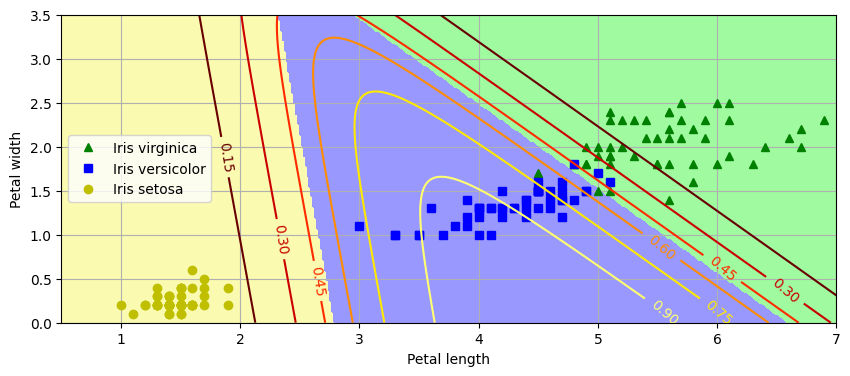

In [ ]:
# extra code – this cell generates and saves Figure 4–25

from matplotlib.colors import ListedColormap

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])

x0, x1 = np.meshgrid(np.linspace(0, 8, 500).reshape(-1, 1),
                     np.linspace(0, 3.5, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)

plt.figure(figsize=(10, 4))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris setosa")

plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap="hot")
plt.clabel(contour, inline=1)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="center left")
plt.axis([0.5, 7, 0, 3.5])
plt.grid()
plt.show()

shows the resulting decision boundaries, represented by the background colors. Notice that the decision
boundaries between any two classes are linear. The figure also shows the probabilities for the Iris versicolor class,
represented by the curved lines (e.g., the line labeled with 0.30 represents the 30% probability boundary). Notice that the
model can predict a class that has an estimated probability below 50%. For example, at the point where all decision
boundaries meet, all classes have an equal estimated probability of 33%.